# Online Shopping Data Analysis
### Customer Behaviour, Product Performance & Peak Sales Periods

**Advanced university-level Python project**

Dataset: UCI Online Retail (ID 352), 541,909 transaction lines, 1 Dec 2010–9 Dec 2011.

This notebook performs data loading, cleaning, exploratory data analysis, RFM feature engineering and K-Means customer segmentation. All reported values are generated from the downloaded dataset when the notebook is run.

## 1. Install dependencies

In [1]:
%pip -q install ucimlrepo scikit-learn seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries and retrieve the official dataset

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

online_retail = fetch_ucirepo(id=352)
raw = online_retail.data.original.copy()
print("Dataset shape:", raw.shape)
display(raw.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


## 3. Data audit

In [4]:
print("Data types:")
display(raw.dtypes.to_frame("dtype"))
print("Missing values:")
display(raw.isna().sum().to_frame("missing_count"))
print("Exact duplicate rows:", raw.duplicated().sum())
display(raw.describe(include="all").T)

Data types:


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


Missing values:


,missing_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Exact duplicate rows: 5268


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data cleaning and feature engineering

Cleaning decisions:
- Remove exact duplicate rows.
- Parse date and numeric columns.
- Exclude cancellation invoices beginning with C from completed-sales analysis.
- Retain positive quantity and positive unit price lines for the main sales analysis.
- Keep missing CustomerID rows for product/time analysis, but exclude them from RFM.
- Calculate line revenue as quantity × unit price.

In [5]:
df = raw.copy()
for col in ["InvoiceNo", "StockCode", "Description", "Country"]:
    df[col] = df[col].astype("string").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

audit = {"raw_rows": len(df)}
df = df.drop_duplicates()
audit["after_exact_deduplication"] = len(df)
df = df.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"])
audit["after_required_field_filter"] = len(df)
cancelled = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
audit["cancellation_rows_excluded"] = int(cancelled.sum())

sales = df.loc[(~cancelled) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
sales["LineRevenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["CustomerID"] = sales["CustomerID"].astype("string").str.replace(r"\.0$", "", regex=True)
audit["positive_sales_rows"] = len(sales)
audit["rows_missing_customer_id"] = int(sales["CustomerID"].isna().sum())
audit["distinct_orders"] = int(sales["InvoiceNo"].nunique())
audit["identified_customers"] = int(sales["CustomerID"].nunique())
audit["distinct_products"] = int(sales["StockCode"].nunique())
audit["countries"] = int(sales["Country"].nunique())
audit["revenue_gbp"] = float(sales["LineRevenue"].sum())

display(pd.Series(audit, name="Value").to_frame())
display(sales.head())

,Value
raw_rows,"541,909.00"
after_exact_deduplication,"536,641.00"
after_required_field_filter,"536,641.00"
cancellation_rows_excluded,"9,251.00"
positive_sales_rows,"524,878.00"
rows_missing_customer_id,"132,186.00"
distinct_orders,"19,960.00"
identified_customers,"4,338.00"
distinct_products,"3,922.00"
countries,38.00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 5. Key performance indicators

In [6]:
kpis = pd.Series({
    "Sales line records": len(sales),
    "Total recorded revenue (£)": sales["LineRevenue"].sum(),
    "Distinct orders": sales["InvoiceNo"].nunique(),
    "Identified customers": sales["CustomerID"].nunique(),
    "Distinct products": sales["StockCode"].nunique(),
    "Countries": sales["Country"].nunique()
}, name="Value")
display(kpis.to_frame())

,Value
Sales line records,"524,878.00"
Total recorded revenue (£),"10,642,110.80"
Distinct orders,"19,960.00"
Identified customers,"4,338.00"
Distinct products,"3,922.00"
Countries,38.00


## 6. Sales trends by month, weekday and hour

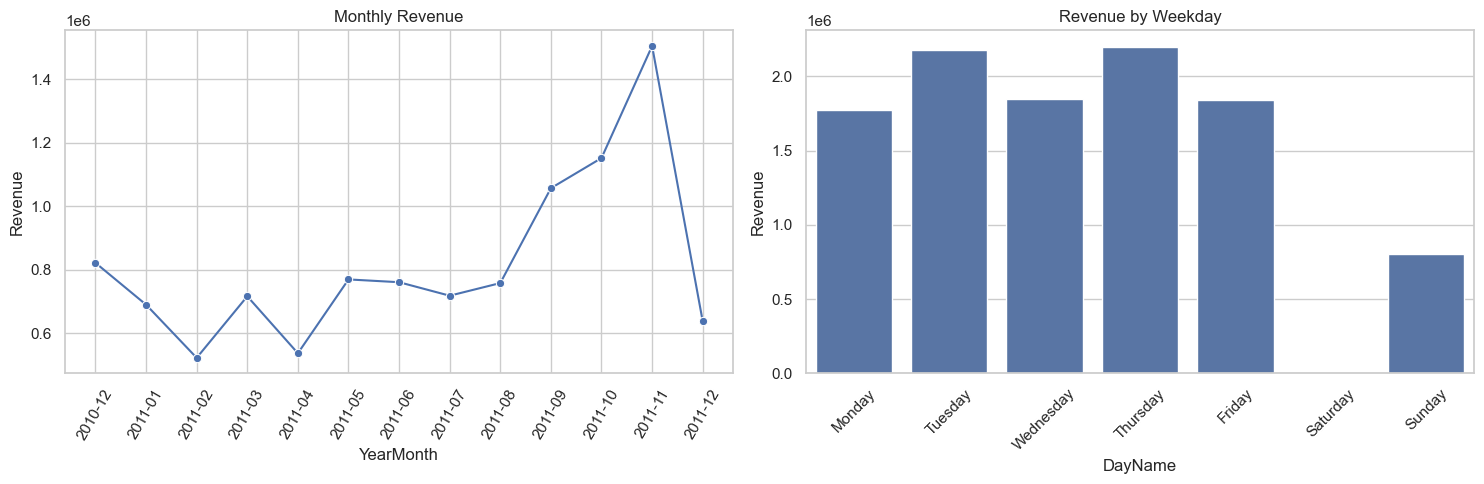

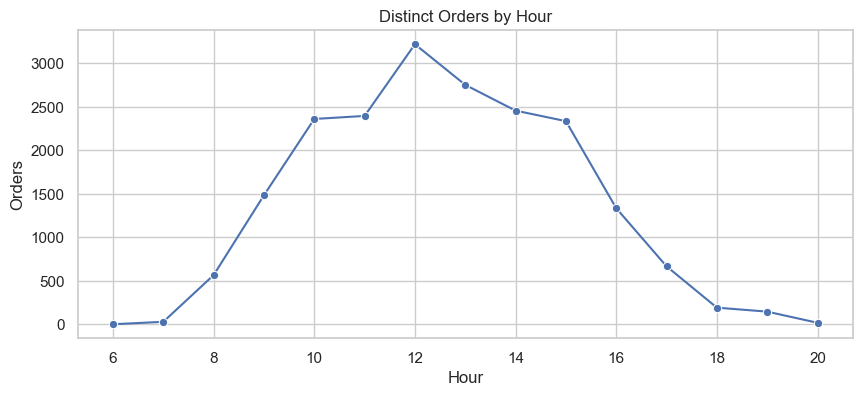

,YearMonth,Revenue,Orders,Units
0,2010-12,"821,452.73",1559,358019
1,2011-01,"689,811.61",1086,387099
2,2011-02,"522,545.56",1100,282934
3,2011-03,"716,215.26",1454,376599
4,2011-04,"536,968.49",1246,307953
5,2011-05,"769,296.61",1681,395001
6,2011-06,"760,547.01",1533,388511
7,2011-07,"718,076.12",1475,399693
8,2011-08,"757,841.38",1361,421020
9,2011-09,"1,056,435.19",1837,569573


,DayName,Revenue,Orders
3,Thursday,"2,199,292.57","4,246.00"
1,Tuesday,"2,175,700.51","3,554.00"
2,Wednesday,"1,847,074.38","3,690.00"
4,Friday,"1,837,470.49","3,140.00"
0,Monday,"1,775,782.07","3,126.00"
6,Sunday,"806,790.78","2,204.00"
5,Saturday,NaN,NaN


,Hour,Revenue,Orders
6,12,"1,439,324.66",3220
7,13,"1,261,195.20",2753
8,14,"1,177,907.52",2457
5,11,"1,236,573.29",2396
4,10,"1,444,814.77",2361
9,15,"1,350,333.31",2336
3,9,"990,054.99",1484
10,16,"752,487.96",1335
11,17,"460,963.92",667
2,8,"283,750.68",566


Important: December 2011 is incomplete; the source ends on 9 December 2011.


In [7]:
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
sales["DayName"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

monthly = sales.groupby("YearMonth").agg(
    Revenue=("LineRevenue", "sum"), Orders=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum")
).reset_index()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = sales.groupby("DayName").agg(
    Revenue=("LineRevenue", "sum"), Orders=("InvoiceNo", "nunique")
).reindex(day_order).reset_index()
hourly = sales.groupby("Hour").agg(
    Revenue=("LineRevenue", "sum"), Orders=("InvoiceNo", "nunique")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=monthly, x="YearMonth", y="Revenue", marker="o", ax=axes[0])
axes[0].set_title("Monthly Revenue")
axes[0].tick_params(axis="x", rotation=60)
sns.barplot(data=daily, x="DayName", y="Revenue", ax=axes[1])
axes[1].set_title("Revenue by Weekday")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=hourly, x="Hour", y="Orders", marker="o", ax=ax)
ax.set_title("Distinct Orders by Hour")
plt.show()

display(monthly)
display(daily.sort_values("Revenue", ascending=False))
display(hourly.sort_values("Orders", ascending=False))
print("Important: December 2011 is incomplete; the source ends on 9 December 2011.")

## 7. Product and country performance

,Revenue,Orders,Customers,Units
Country,,,,
United Kingdom,"9,001,744.09",18019,3920,4646906
Netherlands,"285,446.34",94,9,200361
EIRE,"283,140.52",288,3,147007
Germany,"228,678.40",457,94,119154
France,"209,625.37",392,87,112060
Australia,"138,453.81",57,9,83891
Spain,"61,558.56",90,30,27933
Switzerland,"57,067.60",54,21,30617
Belgium,"41,196.34",98,25,23237


,,Revenue,UnitsSold,Orders
StockCode,Description,,,
DOT,DOTCOM POSTAGE,"206,248.77",706,706
22423,REGENCY CAKESTAND 3 TIER,"174,156.54",13851,1988
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,284.24",37580,2189
47566,PARTY BUNTING,"99,445.23",18283,1685
85099B,JUMBO BAG RED RETROSPOT,"94,159.81",48371,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247
POST,POSTAGE,"78,101.88",3150,1126
M,Manual,"77,750.27",6984,289


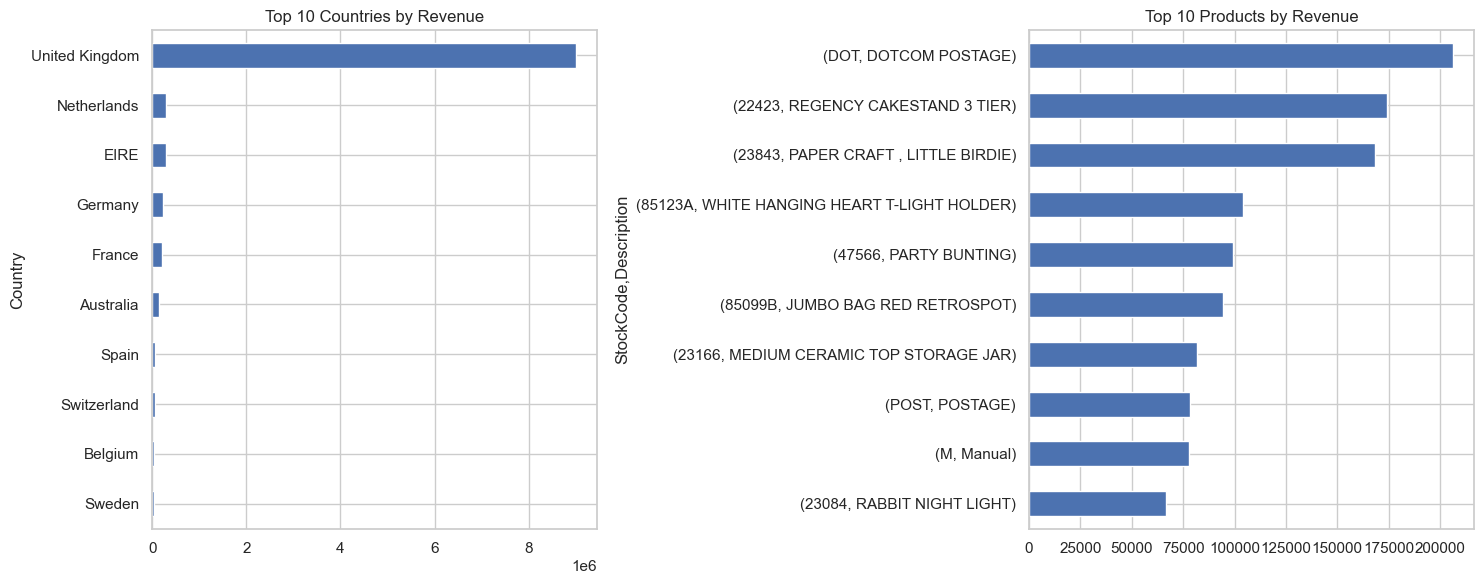

In [8]:
country_perf = sales.groupby("Country").agg(
    Revenue=("LineRevenue", "sum"), Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique"), Units=("Quantity", "sum")
).sort_values("Revenue", ascending=False)
product_perf = sales.groupby(["StockCode", "Description"], dropna=False).agg(
    Revenue=("LineRevenue", "sum"), UnitsSold=("Quantity", "sum"),
    Orders=("InvoiceNo", "nunique")
).sort_values("Revenue", ascending=False)

display(country_perf.head(10))
display(product_perf.head(15))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
country_perf.head(10).sort_values("Revenue").plot(kind="barh", y="Revenue", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Countries by Revenue")
product_perf.head(10).sort_values("Revenue").plot(kind="barh", y="Revenue", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Products by Revenue")
plt.tight_layout()
plt.show()

## 8. Customer RFM analysis

In [9]:
customer_sales = sales.dropna(subset=["CustomerID"]).copy()
snapshot_date = customer_sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = customer_sales.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineRevenue", "sum")
)
rfm = rfm[(rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)].copy()
display(rfm.describe().T)

,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.00",93.06,100.01,1.00,18.00,51.00,142.75,374.00
Frequency,"4,338.00",4.27,7.70,1.00,1.00,2.00,5.00,209.00
Monetary,"4,338.00","2,048.69","8,985.23",3.75,306.48,668.57,"1,660.60","280,206.02"


## 9. K-Means model selection

,k,inertia,silhouette
0,2,"6,476.51",0.43
1,3,"4,858.08",0.34
2,4,"3,925.27",0.33
3,5,"3,269.07",0.32
4,6,"2,840.65",0.31
5,7,"2,532.98",0.31
6,8,"2,325.08",0.30


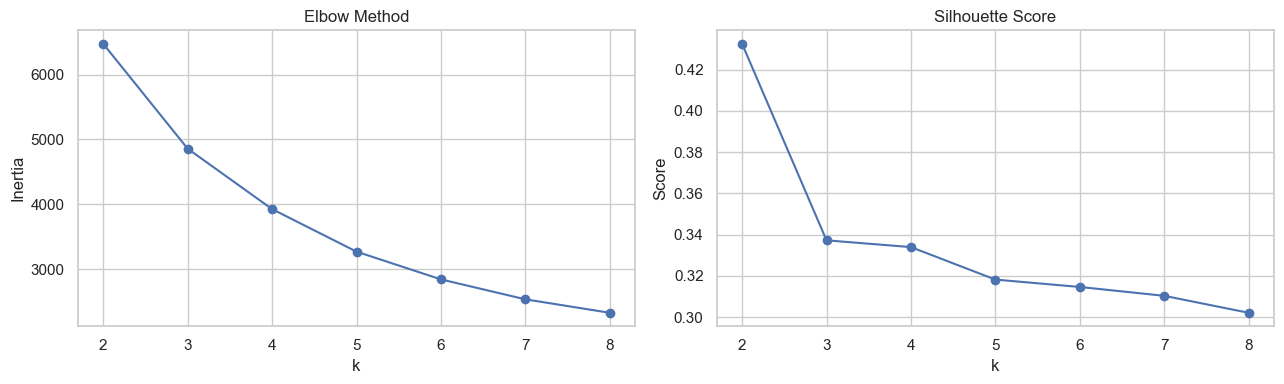

In [10]:
X_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

results = []
models = {}
for k in range(2, min(9, len(rfm))):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })
    models[k] = model

model_scores = pd.DataFrame(results)
display(model_scores)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(model_scores["k"], model_scores["inertia"], marker="o")
axes[0].set(title="Elbow Method", xlabel="k", ylabel="Inertia")
axes[1].plot(model_scores["k"], model_scores["silhouette"], marker="o")
axes[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.show()

## 10. Final customer segments

The baseline below selects the candidate K with the highest silhouette score. Review the Elbow plot and the interpretability of the cluster profiles before presenting this as the final choice. Cluster IDs are arbitrary and must not be named without examining their RFM profiles.

Baseline selected k: 2
Silhouette score: 0.4325


,Customers,AvgRecency,AvgFrequency,AvgMonetary,MedianMonetary,CustomerShare_%
Cluster,,,,,,
0,1668,26.45,8.44,"4,535.74","2,058.17",38.45
1,2670,134.67,1.67,494.98,362.01,61.55


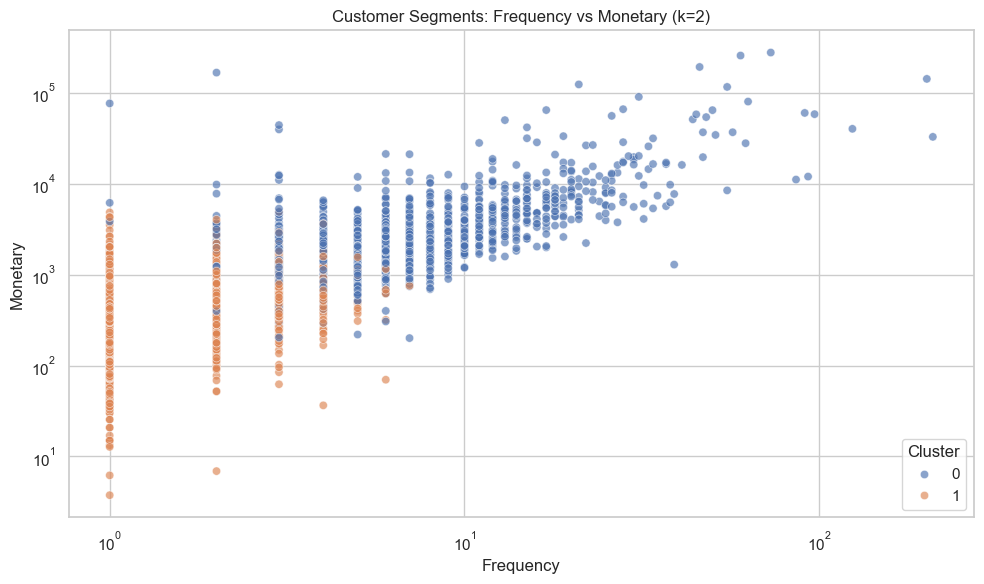

In [11]:
chosen_k = int(model_scores.loc[model_scores["silhouette"].idxmax(), "k"])
final_model = models[chosen_k]
rfm["Cluster"] = final_model.labels_
print("Baseline selected k:", chosen_k)
print("Silhouette score:", round(float(model_scores.loc[model_scores["k"] == chosen_k, "silhouette"].iloc[0]), 4))

cluster_profiles = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median")
).round(2)
cluster_profiles["CustomerShare_%"] = (cluster_profiles["Customers"] / len(rfm) * 100).round(2)
display(cluster_profiles)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=rfm.reset_index(), x="Frequency", y="Monetary",
                hue="Cluster", palette="deep", alpha=.65, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"Customer Segments: Frequency vs Monetary (k={chosen_k})")
plt.tight_layout()
plt.show()

## 11. Findings and business recommendations

Complete the points below using the actual tables and plots above:
- Strongest month / weekday / hour: November 2011 recorded the highest monthly revenue of 1,503,866.78. Thursday recorded the highest weekday revenue of 2,199,292.57, while 12 PM had the highest number of orders (3,220).
- Leading products and countries by recorded revenue: The United Kingdom was the leading country with revenue of 9,001,744.09. The top recorded products/items were DOTCOM POSTAGE (206,248.77), REGENCY CAKESTAND 3 TIER (174,156.54), and PAPER CRAFT, LITTLE BIRDIE (168,469.60).
- Customer segments and their RFM characteristics: -  K-Means identified two customer segments. Cluster 0 contained 1,668 high-value customers with average recency of 26.45 days, frequency of 8.44 purchases, and monetary value of 4,535.74. Cluster 1 contained 2,670 lower-engagement customers with average recency of 134.67 days, frequency of 1.67 purchases, and monetary value of 494.98.

- Business recommendation linked to each finding: Increase stock availability and staffing during high-performing periods, especially November, Thursdays, and around noon. Focus marketing and product availability on the United Kingdom and popular revenue-generating items. Reward high-value customers in Cluster 0 through loyalty programmes and exclusive offers, while targeting Cluster 1 with personalised discounts and re-engagement campaigns.

## 12. Limitations

1. Historical data from 2010–2011 may not represent current shopping behaviour.
2. December 2011 is incomplete.
3. CustomerID is missing for some transaction lines.
4. No product cost data is available; revenue must not be called profit.
5. No formal category, demographic, browsing-session, marketing or inventory data is supplied.
6. K-Means is descriptive clustering, not future-purchase prediction.

## 13. References

Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management, 19*, 197–208. https://doi.org/10.1057/dbm.2012.17